# PGR107 Python Programming | Home Exam 2026
**Bachelor of Data Science, Kristiania University of Applied Sciences**

**Candidates:** xxx & xxx

## How to use
Run the last coding cell to access the menu, which presents our exam submission.


## Imports

In [17]:
import numpy as np
import pandas as pd
import chardet as cd

## Code

In [18]:
def printMenu():
    print()
    print("Which question do you want to run?")
    print("-----------------------------------")
    print("0. Exit")
    print("1. Question 1 - Supernacci")
    print("2. Question 2 - Dice Game")
    print("3. Question 3 - Coordinates")
    print("4. Question 4 - Matrix Trace")
    print("5. Question 5 - Case Study")
    print("-----------------------------------")
    print()

def pressEnterToContinue():
    try:
        print("\nClick OK to continue... (or enter if in terminal)")
        input()
    except KeyboardInterrupt:
        pass

def menu():
    choice = ' '

    while choice not in ('0'):
        printMenu()

        try:
            choice = input("Enter a number: ")
        except KeyboardInterrupt:
            print("\nExiting...")
            break

        match choice:
            case '1':
                question1()
                pressEnterToContinue()
                choice = ' '
            case '2':
                question2()
                pressEnterToContinue()
                choice = ' '
            case '3':
                question3()
                pressEnterToContinue()
                choice = ' '
            case '4':
                question4()
                pressEnterToContinue()
                choice = ' '
            case '5':
                question5()
                pressEnterToContinue()
                choice = ' '
            case '0':
                print("Bye")
            case _:
                print("Invalid choice")

---
## Question 1: Supernacci Numbers

The Supernacci numbers `s(n)` are defined as:
- `s(1) = 1`
- `s(n)` is the sum of the last `(n - 1) % 3` Supernacci numbers, or `s(n-1)` if that sum would be empty (i.e. when `(n-1) % 3 == 0`).

**Strategy:** Build the sequence iteratively in a list. For each new term, we use slicing `s[-j:]` and the built-in `sum()` to compute the value.

In [19]:
def question1():
    def supernacci(n):
        s = [1]
        for i in range(2, n + 1):
            j = (i - 1) % 3
            # When (n-1) % 3 == 0, the slice s[-0:] would mean s[0:], which is the entire list, not an empty one.
            if j == 0:
                # Sum would be empty, use previous term instead
                s.append(s[-1])
            else:
                # Sum of the last j elements using slicing
                s.append(sum(s[-j:]))

        return s[n - 1]

    # Output the first 12 Supernacci numbers to verify the pattern
    print("n  | s(n)")
    print("-----------------------------------")
    for n in range(1, 13):
        print(f"{n:<3}| {supernacci(n)}")

---
## Question 2: Gambling Program

Fixing a bugged implementation of a gambling program.

**Bugs fixed:**
- Typos, all "guesss" instances changed to "guess"
- In getDiceGuess() the return statement was indented inside the while loop
- In getDiceGuess() trailing spaces in `'1 '` etc., user input would never match
- In getDiceGuess() returns a string, but dice is an int. Added `int()` conversion
- In rollDice() `random.randint` changed to `rnd.randint`
- In rollDice() `randint(1, 5)` changed to `randint(1, 4)`
- In rollDice() `if dice = guess:` declaration changed to comparison `==`
- In rollDice() Last `if dice = guess` missing the colon :
- None of the functions get called, added function calls

**Architecture changes:**
- Added checkDice function instead of the last `if` chain. It was unnecessarily indented and
  generally bad practice since it is inconvenient to both read and maintain. Added `maxAttempts`
  variable to facilitate this function.
- Removed "global" variables `dice` and `guess`. Since our implementation uses a menu wrapper,
  they aren't technically global, but nonlocal. Regardless the program becomes more robust
  by confining variables within the scope they are required.


In [20]:
import random as rnd

def question2():
    def getDiceGuess():
        guessRaw = ''
        while guessRaw not in ('1', '2', '3', '4'):
            print('Guess the number on a 4-sided dice! Enter a number between 1 and 4:')
            guessRaw = input()
        return int(guessRaw)

    def checkDice(dice, guess, attempts, maxAttempts):
        if dice == guess:
            print('Correct! Number of attempts:', attempts)
            return True
        else:
            print('Wrong! Remaining attempts:', maxAttempts - attempts)
            return False

    def rollDice():
        roll = rnd.randint(1, 4)
        return roll

    dice = rollDice()
    maxAttempts = 4

    for attempts in range(1, maxAttempts + 1): # lower boundary inclusive, upper exclusive
        guess = getDiceGuess()
        if checkDice(dice, guess, attempts, maxAttempts):
            return

    print('Game over! The number was', dice)

---
## Question 3:

Use the following approximations:

`1 degree of latitude = 111 km`

`1 degree of longitude = 68 km`

Assume that each city has a square shape and that the city size can be added from the center in each direction, as you can see in the image. Ignore the curvature of the Earth when working with latitude and longitude.

a) (6 points) Find the nearest city and POI
 - Function that returns the closest POI for a given pair of coordinates,
 - Function that returns the closest city for a given pair of coordinates.
   Then ask the user to enter a latitude and longitude, and print the closest city and closest POI.

b) (6 points) Compute city boundaries
 - Extend the city data by computing the city boundaries: north, south, east, west.

c) (6 points) Assign POIs to cities
For each city, determine which POIs are located inside its boundaries.
A POI belongs to a city if:
 - its latitude lies between the south and north boundaries
 - its longitude lies between the west and east boundaries

d) (6 points) Compute average POI rating per city
For each city, compute the average customer rating of all POIs located in that city.

e) (6 points) Order POIs by distance from the city center
For each city, create a list of POI names ordered by their distance from the city center, from nearest to farthest.

In [21]:
def question3():

    latitudeMultiplier = 111
    longitudeMultiplier = 68

    cities = {'Bergen':    [60.364098, 5.404422,  15],
              'Oslo':      [59.926959, 10.779454, 10],
              'Trondheim': [63.433654, 10.390277, 5]
    }

    poi = {(63.426806, 10.396712): ['Nidarosdommen',     4.5],
           (59.926699, 10.701075): ['Vigelandsparken',   5],
           (59.907704, 10.753163): ['Operahuset',        4],
           (60.397561, 5.322833):  ['Bryggen',           4.5],
           (60.387639, 5.321623):  ['Universitetmuseet', 5],
           (60.342901, 5.336796):  ['Gamlehaugen',       4]
    }

    # Task a: Find the nearest city and POI
    def returnClosestPoi(userCoords):
        shortestDistance = np.inf
        closestPoi       = None
        closestCoords    = None

        print("\n--| Searching POIs |--")
        for coords, data in poi.items():
            poiLatitude  = coords[0]
            poiLongitude = coords[1]
            print(f"  Testing POI: {data[0]:<20} at ({poiLatitude}, {poiLongitude})")

            latitudeDistance  = abs(userCoords[0] - poiLatitude)  * latitudeMultiplier
            longitudeDistance = abs(userCoords[1] - poiLongitude) * longitudeMultiplier
            distance = latitudeDistance + longitudeDistance

            if distance < shortestDistance:
                shortestDistance = distance
                closestPoi       = data
                closestCoords    = coords

        return closestPoi, closestCoords

    def returnClosestCity(userCoords):
        shortestDistance = np.inf
        closestCity      = None
        closestCoords    = None

        print("\n--| Searching Cities |--")
        for city, values in cities.items():
            cityLatitude  = values['center'][0]
            cityLongitude = values['center'][1]
            print(f"  Testing City: {city:<12} at ({cityLatitude}, {cityLongitude})")

            latitudeDistance  = abs(userCoords[0] - cityLatitude)  * latitudeMultiplier
            longitudeDistance = abs(userCoords[1] - cityLongitude) * longitudeMultiplier
            distance = latitudeDistance + longitudeDistance

            if distance < shortestDistance:
                shortestDistance = distance
                closestCity      = city
                closestCoords    = [cityLatitude, cityLongitude]

        return closestCity, closestCoords

    def getUserCoords():
        try:
            while True:
                try:
                    userLatitude = float(input("Enter your latitude: "))
                    break
                except ValueError:
                    print("Invalid input.")

            while True:
                try:
                    userLongitude = float(input("Enter your longitude: "))
                    break
                except ValueError:
                    print("Invalid input.")

            return [userLatitude, userLongitude]

        except KeyboardInterrupt:
            print("\nExiting...")
            return None

    # Task b: Extend cities with boundaries
    def setCityBoundaries():
        for city, values in cities.items():
            lat, lon, size = values[0], values[1], values[2]
            cities[city] = {
                'center': [lat, lon],
                'size':   size,
                'north':  lat + (size / latitudeMultiplier),
                'south':  lat - (size / latitudeMultiplier),
                'east':   lon + (size / longitudeMultiplier),
                'west':   lon - (size / longitudeMultiplier)
            }

    # Task c: Assign POIs to cities
    def setCityPois():
        for city in cities:
            cities[city]['pois'] = []

        for coords, data in poi.items():
            poiLat, poiLon = coords[0], coords[1]

            for city, values in cities.items():
                insideLat = values['south'] <= poiLat <= values['north']
                insideLon = values['west']  <= poiLon <= values['east']

                if insideLat and insideLon:
                    values['pois'].append(data)

    # Task d: Compute average POI rating per city
    def computeAvgRatings():
        for city, values in cities.items():
            ratings = [p[1] for p in values['pois']]
            values['avgRating'] = sum(ratings) / len(ratings)

    # Task e: Order POIs by distance from city center
    def sortPoisByDistance():
        for city, values in cities.items():
            cityLat = values['center'][0]
            cityLon = values['center'][1]

            distances = []
            for coords, data in poi.items():
                if data in values['pois']:
                    latDist  = abs(cityLat - coords[0]) * latitudeMultiplier
                    lonDist  = abs(cityLon - coords[1]) * longitudeMultiplier
                    distances.append((latDist + lonDist, data[0]))

            distances.sort()
            values['poisByDistance'] = distances

    # Main flow
    print("Find the closest POI or city based on your coordinates")
    userCoords = getUserCoords()

    if userCoords is None:
            return

    setCityBoundaries()
    setCityPois()
    computeAvgRatings()
    sortPoisByDistance()

    closestPoi,  poiCoords  = returnClosestPoi(userCoords)
    closestCity, cityCoords = returnClosestCity(userCoords)

    print("\n--| Results |--")
    print(f"  {'User coordinates:':<18} {'':<20}  ({userCoords[0]}, {userCoords[1]})")
    print(f"  {'Closest POI:':<18} {closestPoi[0]:<20}  ({poiCoords[0]}, {poiCoords[1]})")
    print(f"  {'Closest City:':<18} {closestCity:<20}  ({cityCoords[0]}, {cityCoords[1]})")

    print("\n--| City Boundaries |--")
    for city, values in cities.items():
        print(f"  {city} (center: {values['center']}, size: {values['size']} km)")
        print(f"    north: {values['north']:.6f}    south: {values['south']:.6f}")
        print(f"    east:  {values['east']:9.6f}    west:  {values['west']:9.6f}")

    print("\n--| POIs per City |--")
    for city, values in cities.items():
        print(f"  {city:<12} {[f'{p[0]} ({p[1]})' for p in values['pois']]}")
    print()

    print("\n--| Average POI Rating per City |--")
    for city, values in cities.items():
        print(f"  {city:<12} avg rating: {values['avgRating']:.2f}")

    print("\n--| POIs by Distance from City Center |--")
    for city, values in cities.items():
        print(f"  {city}")
        for distance, name in values['poisByDistance']:
            print(f"    {name:<20} {distance:.2f} km")

    print()

---
## Question 4: Matrix Trace

Given a rank 2 numpy array A (a matrix), check whether the number of columns equals the number of rows. If (and only if) they coincide, compute and output the sum of elements on the main diagonal.

**Strategy:** First implement manually by iterating over the diagonal indices `A[i, i]`. Then verify the result using NumPy's built-in `np.trace()` to confirm correctness.

In [22]:
def question4():
    def trace(A):
        # check whether the number of columns equals the number of rows
        if A.shape[0] != A.shape[1]:
            print("Invalid matrix, trace operation aborted.")
            return

        # Manual implementation: sum diagonal elements A[i, i]
        total = 0
        for i in range(A.shape[0]):
            total += A[i, i]

        print(f"Manual trace:    {total}")

        # np.trace() used to verify our manual result is correct
        print(f"np.trace():      {np.trace(A)}\n")

    A = np.array([[1, 2, 3],
                  [4, 5, 6],
                  [7, 8, 9]])
    B = np.array([[3, 1, 7],
                  [7, 1, 4],
                  [2, 8, 5]])
    C = np.array([[1, 2, 3],
                  [4, 5, 6]])


    print(f"Matrix A:\n{A}")
    trace(A)
    print(f"Matrix B:\n{B}")
    trace(B)
    print(f"Matrix C:\n{C}")
    trace(C)

### 5.1 — Data Selection

We downloaded the *karakterstatistikk* dataset from Utdanningsdirektoratet covering Oslo high schools. Filters applied on download and in code:

- **Enhet (school level):** Individual Oslo schools only (`EnhetNivaa == 3`, `Fylke == 'Oslo'`). National, county, and aggregate rows are excluded.
- **Karaktertype:** Skriftlig eksamen (written exam). Written exams are externally set and marked, making them a more objective and comparable signal than standpunkt grades, which are school-set and therefore more susceptible to institutional grade inflation.
- **School years:** 2020–21 through 2024–25 (five years — pre-COVID baseline through post-COVID recovery).
- **Subject selection:** All available written exam subjects for Oslo schools. Subjects are grouped into *utdanningsprogrammer* (education programmes) using the two-character prefix of the `Vurderingsfagkode` (e.g. `RE` → Realfag, `SA` → Samfunnsfag).

The file is a tab-separated, UTF-16-LE encoded CSV. Encoding is detected automatically, grade columns converted from Norwegian decimal format (comma → dot), and suppressed values (`*`) replaced with `NaN`.

---

### 5.2 — Exploratory Visualization

See the visualizations generated by the implementation below. Each panel is labeled and covers a distinct aspect of the data.

---

### 5.3 — Problem Definition and Analysis

**Research question:**
Have written exam grades at Oslo high schools drifted upward between 2020 and 2025 across all utdanningsprogrammer, or only specific ones? (Post-COVID grade inflation is a documented concern in Norwegian education.)

**Background:**
During COVID-19, Norwegian high schools suspended written exams in 2020 and 2021, relying solely on standpunkt grades. When written exams resumed, both teaching practices and grading norms had shifted. Research and media reporting (e.g. Aftenposten, SSB) have noted that standpunkt grades rose markedly during the pandemic and did not fully revert. The question here is whether *written exam* grades — externally set — show a similar upward drift across Oslo's schools from 2020 to 2025.

**Hypotheses:**
- **H1 (Systemic inflation):** Mean written exam grades across Oslo schools have increased from 2020–2025, indicating grade inflation that persists beyond the COVID disruption years.
- **H2 (Programme-level variation):** The rate and magnitude of grade drift differs by utdanningsprogram — some programmes (e.g. academic Realfag or Samfunnsfag) may show stronger or more consistent upward trends than others.

**Implementation — visualizations used:**

The analysis uses a multi-panel figure (`fig.add_subplot` / `fig.subplots_adjust`) with the following chart types:

- **Histogram** (`plt.hist`) — overlay the grade distribution for the first year (2020–21) and the last year (2024–25) using alpha transparency, showing any rightward shift in the overall distribution.
- **Error bars** (`plt.errorbar`) — plot the overall mean written exam grade per year with ±1 standard deviation bars, showing whether the aggregate trend is upward and how variance evolves. Per-programme lines are overlaid lightly in the background.
- **Line plot** (`plt.plot`) — one line per utdanningsprogram showing average grade across years, making programme-level trends and their relative ordering visible over time.
- **Scatter plot** (`plt.plot` with markers) — individual Oslo school averages per year per programme, revealing how consistently (or inconsistently) the drift appears across institutions.
- **Contour/density plot** (`plt.contour` on `np.meshgrid`) — 2D density of (avg grade 2020–21, avg grade 2024–25) pairs per school/programme. A reference diagonal (y = x) marks zero grade change; schools above it have inflated. The density contour shows where most schools cluster relative to that boundary.
- **Legends** (`ax.legend`, `ax.add_artist`) — programmes are consistently coloured across all panels. The scatter+contour panel uses two separate legends (programmes + contour reference) via `ax.add_artist()`.

Each subplot is labeled with title, x-axis label, and y-axis label. Conclusions are drawn from what the charts show.

---

### Sources

Utdanningsdirektoratet. (2025). *Karakterstatistikk for videregående skole.*
https://www.udir.no/tall-og-forskning/statistikk/statistikk-videregaende-skole/karakterer-vgs/


In [23]:
import matplotlib.pyplot as plt
import matplotlib.legend as mlegend

def question5():

    # --- Load & clean ---
    def loadDataset(filepath):
        with open(filepath, 'rb') as f:
            result = cd.detect(f.read(10000))
        print(f"  Detected encoding: {result['encoding']} (confidence: {result['confidence']:.0%})")

        df = pd.read_csv(filepath, sep='\t', encoding=result['encoding'], skiprows=1)

        # Filter: Oslo individual schools only
        df = df[(df['Fylke'] == 'Oslo') & (df['EnhetNivaa'] == 3)].reset_index(drop=True)

        grade_cols = df.columns[10:]
        df[grade_cols] = df[grade_cols].replace('*', np.nan)
        for col in grade_cols:
            df[col] = pd.to_numeric(
                df[col].astype(str).str.replace(',', '.', regex=False),
                errors='coerce'
            )
        return df

    df = loadDataset('dataset.csv')

    # Identify Skriftlig eksamen snitt columns dynamically
    snitt_cols = [c for c in df.columns if 'Skriftlig eksamen' in c and 'Snittkarakter' in c]
    years      = [c.split('.')[0] for c in snitt_cols]

    # Map 2-char subject code prefix → utdanningsprogram
    program_map = {
        'RE': 'Realfag',           'SA': 'Samfunnsfag',
        'FS': 'Fremmedspråk',      'PS': 'Fremmedspråk',
        'SP': 'Fremmedspråk',      'SF': 'Fremmedspråk',
        'NO': 'Fellesfag',         'MA': 'Fellesfag',
        'EN': 'Fellesfag',         'ID': 'Idrettsfag',
        'MU': 'Musikk/dans/drama', 'DA': 'Musikk/dans/drama',
        'DR': 'Musikk/dans/drama', 'MO': 'Medier og komm.',
        'AU': 'Yrkesfag',          'EL': 'Yrkesfag',
        'BU': 'Yrkesfag',          'LB': 'Yrkesfag',
        'LO': 'Yrkesfag',          'SL': 'Yrkesfag',
    }
    df['program'] = df['Vurderingsfagkode'].str[:2].map(program_map).fillna('Andre')

    # --- Summary ---
    schools = list(df['EnhetNavn'].unique())

    print(f"\n--| Dataset Summary |--")
    print(f"  Rows: {len(df)}   Columns: {len(df.columns)}")
    print(f"  Filter: Fylke == 'Oslo', EnhetNivaa == 3 (individual schools)")
    print(f"  Assessment: Skriftlig eksamen (written exam)")
    print(f"  Years: {', '.join(years)}")
    print(f"  Schools ({len(schools)}):")
    for s in schools:
        print(f"    {s}")

    # --- Build long-form DataFrame ---
    records = []
    for _, row in df.iterrows():
        for year, col in zip(years, snitt_cols):
            val = row[col]
            if not pd.isna(val):
                records.append({
                    'school':  row['EnhetNavn'],
                    'program': row['program'],
                    'year':    year,
                    'grade':   val
                })
    df_long = pd.DataFrame(records)

    if df_long.empty:
        print("  No Skriftlig eksamen data found.")
        return

    # Count observations per year — written exams were cancelled in 2020-21 and 2021-22 (COVID)
    print(f"\n--| Observations per Year |--")
    year_counts = {}
    for year in years:
        n = df_long[df_long['year'] == year]['grade'].count()
        year_counts[year] = n
        print(f"  {year}: {n} observations")

    # Use first and last year that have enough data for meaningful comparison
    THRESHOLD = 20
    years_ok  = [y for y in years if year_counts[y] >= THRESHOLD]
    yr_first  = years_ok[0]  if years_ok else years[0]
    yr_last   = years_ok[-1] if years_ok else years[-1]
    print(f"\n  Comparing: {yr_first} (first usable year) → {yr_last} (last year)")

    # Programme stats
    prog_stats    = df_long.groupby('program')['grade'].agg(['mean', 'std', 'count']).sort_values('mean')
    programs_rank = prog_stats.index.tolist()

    print(f"\n--| Programme Summary (mean written exam grade, hardest → easiest) |--")
    for prog, r in prog_stats.iterrows():
        print(f"  {prog:<25}  avg={r['mean']:.2f}  std={r['std']:.2f}  n={int(r['count'])}")

    print(f"\n--| Year-by-Year Mean Grades (all Oslo schools, all programmes) |--")
    for year in years:
        v = df_long[df_long['year'] == year]['grade'].values
        if len(v):
            print(f"  {year}:  mean={np.nanmean(v):.2f}  std={np.nanstd(v):.2f}  n={len(v)}")

    # Helper: mean and std for a (programme, year) slice
    def prog_yr_stats(prog, year):
        v = df_long[(df_long['program'] == prog) & (df_long['year'] == year)]['grade'].values
        return (np.nanmean(v) if len(v) else np.nan,
                np.nanstd(v)  if len(v) else 0)

    # School avg per programme per year
    school_prog_yr = df_long.groupby(['school', 'program', 'year'])['grade'].mean().reset_index()

    # Colors and markers — one per programme, consistent across all panels
    n          = len(programs_rank)
    colors     = [plt.cm.tab10(i % 10) for i in range(n)]
    prog_color = dict(zip(programs_rank, colors))
    markers    = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', 'h', 'p']

    # --- Figure: 3×2 subplots ---
    fig = plt.figure(figsize=(16, 14))
    fig.subplots_adjust(hspace=0.55, wspace=0.35)

    # --- Panel 1: Histogram — first vs last usable year, density-normalised (H1) ---
    ax1 = fig.add_subplot(3, 2, 1)
    bins         = np.linspace(1, 6, 18)
    grades_first = df_long[df_long['year'] == yr_first]['grade'].values
    grades_last  = df_long[df_long['year'] == yr_last ]['grade'].values
    hist_kwargs  = dict(bins=bins, histtype='stepfilled', alpha=0.55, density=True)
    ax1.hist(grades_first, color='steelblue', label=yr_first, **hist_kwargs)
    ax1.hist(grades_last,  color='tomato',    label=yr_last,  **hist_kwargs)
    ax1.set(title=f'H1: Grade Distribution — {yr_first} vs {yr_last}',
            xlabel='Grade (1–6)', ylabel='Density')
    ax1.legend(loc='upper left', frameon=True)

    # --- Panel 2: Error bars — overall mean ± std per year (H1) ---
    ax2 = fig.add_subplot(3, 2, 2)
    x         = np.arange(len(years))
    all_means = [np.nanmean(df_long[df_long['year'] == y]['grade'].values) for y in years]
    all_stds  = [np.nanstd( df_long[df_long['year'] == y]['grade'].values) for y in years]
    for prog, color in zip(programs_rank, colors):
        ms = [prog_yr_stats(prog, y)[0] for y in years]
        ax2.plot(x, ms, color=color, linewidth=1, alpha=0.4, marker='.')
    ax2.errorbar(x, all_means, yerr=all_stds, color='black',
                 capsize=5, linewidth=2.5, marker='o', markersize=7, elinewidth=1.5,
                 label='All programmes (mean ± std)', zorder=5)
    ax2.set(title='H1: Overall Mean Written Exam Grade per Year (±std)',
            xlabel='Year', ylabel='Mean Grade')
    ax2.set_xticks(x)
    ax2.set_xticklabels(years, rotation=30, fontsize=7)
    ax2.set_ylim(1, 6)
    ax2.legend(loc='upper left', fontsize=8, frameon=True)

    # --- Panel 3: Line plot — avg grade per programme per year (H2) ---
    ax3 = fig.add_subplot(3, 2, 3)
    for prog, color in zip(programs_rank, colors):
        means = [prog_yr_stats(prog, y)[0] for y in years]
        ax3.plot(years, means, color=color, label=prog,
                 linewidth=2, marker='o', markersize=5)
    ax3.set(title='H2: Avg Written Exam Grade per Programme Over Years',
            xlabel='Year', ylabel='Mean Grade')
    ax3.set_ylim(1, 6)
    for t in ax3.get_xticklabels():
        t.set_rotation(30)
        t.set_fontsize(7)
    ax3.legend(loc='upper left', fontsize=7, frameon=True)

    # --- Panel 4: Scatter — individual school avg per year, coloured by programme (H2) ---
    ax4 = fig.add_subplot(3, 2, 4)
    yr_idx = {y: i for i, y in enumerate(years)}
    jitter = np.linspace(-0.3, 0.3, n)
    for pi, prog in enumerate(programs_rank):
        rows = school_prog_yr[school_prog_yr['program'] == prog]
        for _, r in rows.iterrows():
            ax4.plot(yr_idx[r['year']] + jitter[pi], r['grade'],
                     markers[pi % len(markers)],
                     color=prog_color[prog], markersize=5, alpha=0.6)
    ax4.set_xticks(range(len(years)))
    ax4.set_xticklabels(years, rotation=30, fontsize=7)
    ax4.set_ylim(1, 6)
    ax4.set(title='H2: Individual School Avg Grades per Year',
            xlabel='Year', ylabel='Avg Grade')
    prog_handles = [
        plt.Line2D([0], [0], marker=markers[i % len(markers)], color=colors[i],
                   linewidth=0, markersize=6, label=programs_rank[i])
        for i in range(n)
    ]
    ax4.legend(handles=prog_handles, loc='upper left', fontsize=6, frameon=True)

    # --- Panel 5: Scatter + Contour — programme avg first vs last usable year (H1/H2) ---
    # Uses programme-level averages (not school-level) so all programmes with data appear.
    ax5 = fig.add_subplot(3, 2, 5)

    prog_avg_first = df_long[df_long['year'] == yr_first].groupby('program')['grade'].mean()
    prog_avg_last  = df_long[df_long['year'] == yr_last ].groupby('program')['grade'].mean()
    common_progs   = prog_avg_first.index.intersection(prog_avg_last.index).tolist()

    x_pts = np.array([prog_avg_first[p] for p in common_progs])
    y_pts = np.array([prog_avg_last[p]  for p in common_progs])

    # Reference diagonal: y = x means no grade change
    diag_min = min(x_pts.min(), y_pts.min()) - 0.3
    diag_max = max(x_pts.max(), y_pts.max()) + 0.3
    ax5.plot([diag_min, diag_max], [diag_min, diag_max], 'k--', linewidth=1, alpha=0.6)

    scatter_handles_5 = []
    for pi, prog in enumerate(programs_rank):
        if prog in common_progs:
            idx = common_progs.index(prog)
            h, = ax5.plot(x_pts[idx], y_pts[idx],
                          markers[pi % len(markers)], color=colors[pi],
                          markersize=10, alpha=0.9, label=prog)
            scatter_handles_5.append(h)

    # Gaussian KDE contour using np.meshgrid (lec11.4 / lec8.3 technique)
    if len(x_pts) >= 3:
        pad = 0.3
        xg  = np.linspace(x_pts.min() - pad, x_pts.max() + pad, 50)
        yg  = np.linspace(y_pts.min() - pad, y_pts.max() + pad, 50)
        X, Y = np.meshgrid(xg, yg)
        Z    = np.zeros_like(X)
        bw   = 0.3
        for xi, yi in zip(x_pts, y_pts):
            Z += np.exp(-((X - xi)**2 + (Y - yi)**2) / (2 * bw**2))
        ax5.contour(X, Y, Z, levels=6, cmap='RdGy')

    ax5.set(title=f'H1/H2: Programme Avg — {yr_first} vs {yr_last}\n(above diagonal = grade inflation)',
            xlabel=f'Avg grade {yr_first}',
            ylabel=f'Avg grade {yr_last}')

    # Two separate legends via mlegend.Legend + add_artist() (P11.1 pattern)
    leg1 = mlegend.Legend(ax5, scatter_handles_5,
                           [h.get_label() for h in scatter_handles_5],
                           loc='upper left', fontsize=6, title='Programme', frameon=True)
    diag_handle = plt.Line2D([0], [0], color='k', linewidth=1, linestyle='--')
    cont_handle = plt.Line2D([0], [0], color='dimgray', linewidth=1.5)
    leg2 = mlegend.Legend(ax5, [diag_handle, cont_handle],
                           ['No change (y = x)', 'Density contour'],
                           loc='lower right', fontsize=6, frameon=True)
    ax5.add_artist(leg1)
    ax5.add_artist(leg2)

    # --- Panel 6: Bar chart — grade change magnitude per programme (H2) ---
    ax6 = fig.add_subplot(3, 2, 6)
    deltas = []
    for prog in programs_rank:
        first = prog_yr_stats(prog, yr_first)[0]
        last  = prog_yr_stats(prog, yr_last)[0]
        deltas.append(last - first if not (np.isnan(first) or np.isnan(last)) else np.nan)
    bar_colors = ['tomato' if (not np.isnan(d) and d > 0) else 'steelblue' for d in deltas]
    ax6.bar(range(len(programs_rank)), deltas, color=bar_colors, alpha=0.85)
    ax6.axhline(0, color='black', linewidth=0.8)
    ax6.set_xticks(range(len(programs_rank)))
    ax6.set_xticklabels([p[:14] for p in programs_rank],
                        rotation=45, ha='right', fontsize=7)
    ax6.set(title=f'H2: Grade Change per Programme\n({yr_first} → {yr_last}, red = inflation)',
            xlabel='Programme', ylabel='Δ Mean Grade')

    plt.suptitle('Oslo High Schools — Written Exam Grade Inflation Analysis (2020–2025)',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.show()



Which question do you want to run?
-----------------------------------
0. Exit
1. Question 1 - Supernacci
2. Question 2 - Dice Game
3. Question 3 - Coordinates
4. Question 4 - Matrix Trace
5. Question 5 - Case Study
-----------------------------------

  Detected encoding: utf-16-le (confidence: 95%)

--| Dataset Summary |--
  Rows: 1123   Columns: 51
  Filter: Fylke == 'Oslo', EnhetNivaa == 3 (individual schools)
  Assessment: Skriftlig eksamen (written exam)
  Years: 2020-21, 2021-22, 2022-23, 2023-24, 2024-25
  Schools (40):
    Kuben videregående skole
    Etterstad videregående skole
    Edvard Munch videregående skole
    Hartvig Nissens skole
    Elvebakken videregående skole
    Hersleb videregående skole
    Stovner videregående skole
    Privatistkontoret i Oslo
    Akademiet Oslo AS
    Akademiet Vgs Bislett AS
    Bjerke videregående skole
    Bjørnholt videregående skole
    Blindern videregående skole
    Foss videregående skole
    Fyrstikkalleen skole
    Hellerud vide

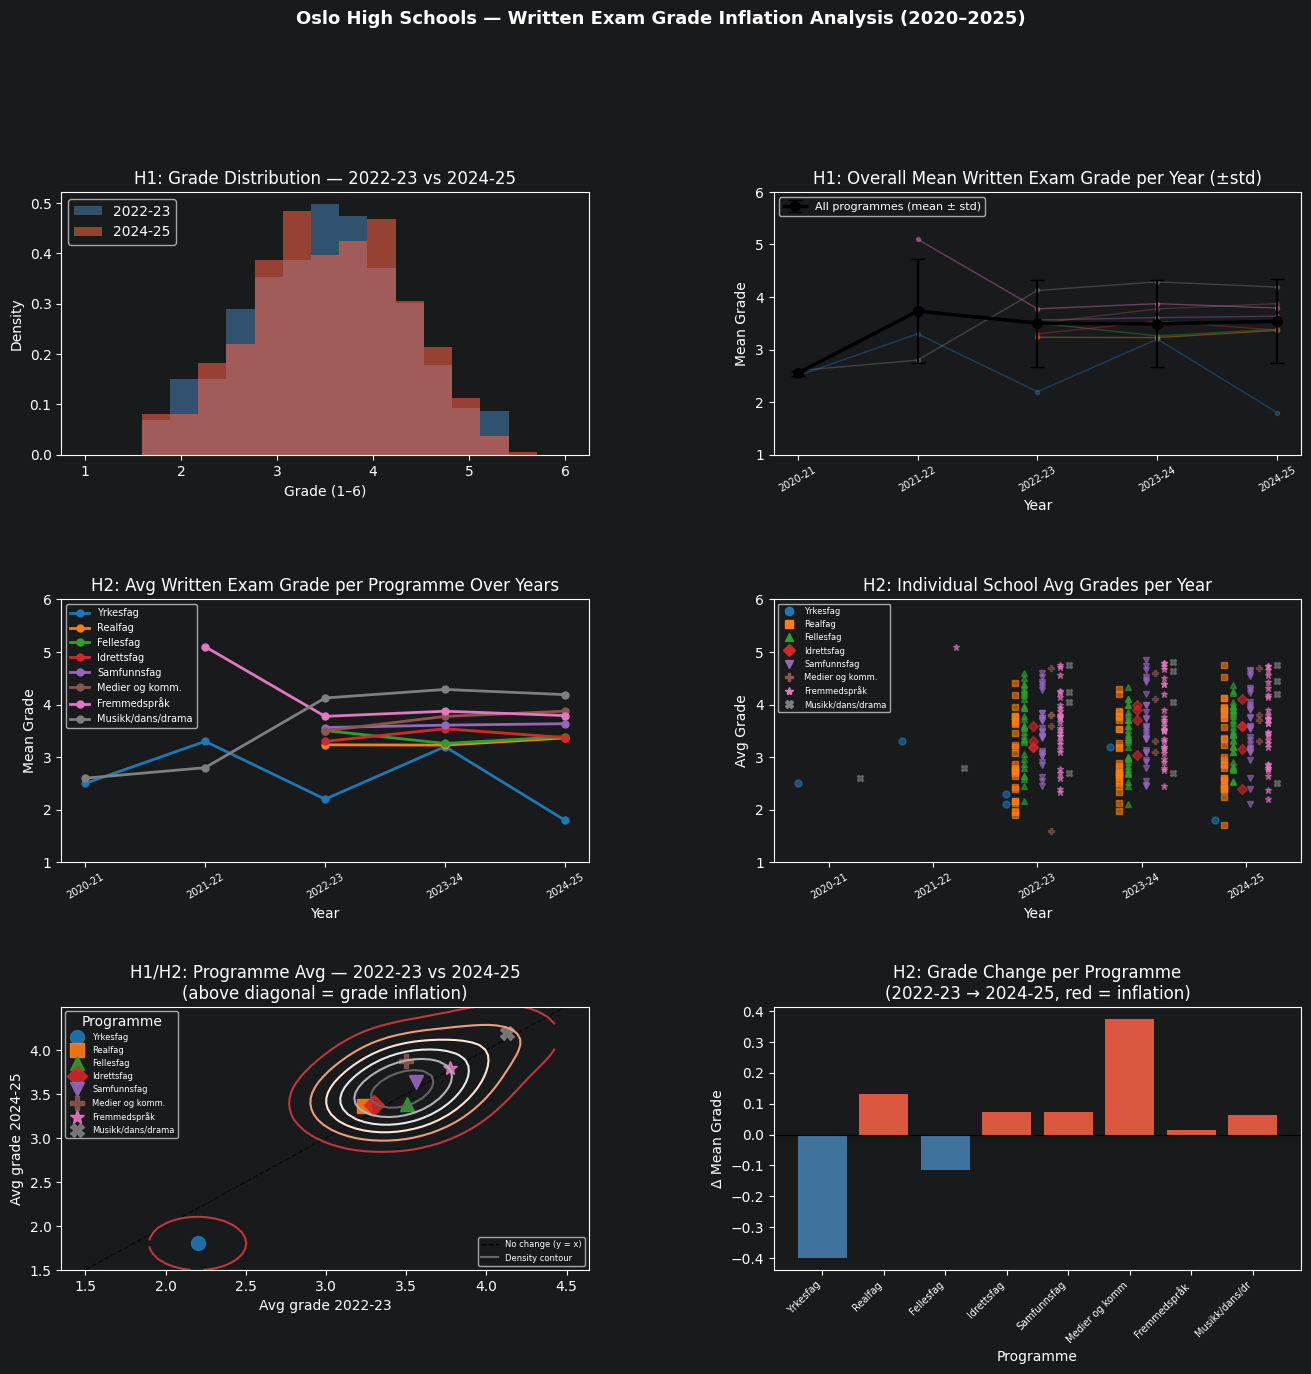


Click OK to continue... (or enter if in terminal)

Which question do you want to run?
-----------------------------------
0. Exit
1. Question 1 - Supernacci
2. Question 2 - Dice Game
3. Question 3 - Coordinates
4. Question 4 - Matrix Trace
5. Question 5 - Case Study
-----------------------------------


Exiting...


In [24]:
menu()